# ELEVVO NLP INTERNSHIP
# Named Entity Recognition (NER) from News Articles

Install Libraries

In [3]:
!pip install spacy pandas matplotlib seaborn -q
!python -m spacy download en_core_web_sm -q


✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


Import Libraries

In [4]:
import spacy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from spacy import displacy

print("spaCy Version:", spacy.__version__)
print("Libraries imported successfully!")


spaCy Version: 3.8.18
Libraries imported successfully!


Load spaCy Model

In [5]:
nlp = spacy.load("en_core_web_sm")

print("spaCy Model Loaded Successfully!")
print("Pipeline Components:", nlp.pipe_names)


spaCy Model Loaded Successfully!
Pipeline Components: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


Create Sample News Articles

In [6]:

news_articles = [
    {
        "article_id": 1,
        "article": "Microsoft CEO Satya Nadella visited London to discuss artificial intelligence and technology."
    },
    {
        "article_id": 2,
        "article": "OpenAI CEO Sam Altman met technology experts in New York to discuss AI development."
    },
    {
        "article_id": 3,
        "article": "Google announced a new research initiative in California with support from international universities."
    },
    {
        "article_id": 4,
        "article": "The United Nations organized a technology conference in Paris on January 15, 2026."
    },
    {
        "article_id": 5,
        "article": "Apple and Microsoft discussed cybersecurity improvements during a meeting in Washington."
    }
]

df = pd.DataFrame(news_articles)

print("Total News Articles:", len(df))
display(df)


Total News Articles: 5


,article_id,article
0,1,Microsoft CEO Satya Nadella visited London to ...
1,2,OpenAI CEO Sam Altman met technology experts i...
2,3,Google announced a new research initiative in ...
3,4,The United Nations organized a technology conf...
4,5,Apple and Microsoft discussed cybersecurity im...


Model-Based Named Entity Recognition

In [7]:
model_results = []

for index, row in df.iterrows():
    doc = nlp(row["article"])

    for ent in doc.ents:
        model_results.append({
            "Article ID": row["article_id"],
            "Entity": ent.text,
            "Entity Label": ent.label_,
            "Category": spacy.explain(ent.label_)
        })

model_df = pd.DataFrame(model_results)

print("Model-Based NER Results:")
display(model_df)

Model-Based NER Results:


,Article ID,Entity,Entity Label,Category
0,1,Microsoft,ORG,"Companies, agencies, institutions, etc."
1,1,Satya Nadella,PERSON,"People, including fictional"
2,1,London,GPE,"Countries, cities, states"
3,2,OpenAI,ORG,"Companies, agencies, institutions, etc."
4,2,Sam Altman,PERSON,"People, including fictional"
5,2,New York,GPE,"Countries, cities, states"
6,3,Google,ORG,"Companies, agencies, institutions, etc."
7,3,California,GPE,"Countries, cities, states"
8,4,United Nations,ORG,"Companies, agencies, institutions, etc."
9,4,Paris,GPE,"Countries, cities, states"


Rule-Based NER using EntityRuler

In [8]:
rule_nlp = spacy.load("en_core_web_sm")

ruler = rule_nlp.add_pipe(
    "entity_ruler",
    before="ner"
)

patterns = [
    {"label": "PERSON", "pattern": "Satya Nadella"},
    {"label": "PERSON", "pattern": "Sam Altman"},
    {"label": "ORG", "pattern": "Microsoft"},
    {"label": "ORG", "pattern": "OpenAI"},
    {"label": "ORG", "pattern": "Google"},
    {"label": "ORG", "pattern": "Apple"},
    {"label": "ORG", "pattern": "United Nations"},
    {"label": "GPE", "pattern": "London"},
    {"label": "GPE", "pattern": "New York"},
    {"label": "GPE", "pattern": "California"},
    {"label": "GPE", "pattern": "Paris"},
    {"label": "GPE", "pattern": "Washington"}
]

ruler.add_patterns(patterns)

rule_results = []

with rule_nlp.select_pipes(disable=["ner"]):
    for index, row in df.iterrows():
        doc = rule_nlp(row["article"])

        for ent in doc.ents:
            rule_results.append({
                "Article ID": row["article_id"],
                "Entity": ent.text,
                "Entity Label": ent.label_
            })

rule_df = pd.DataFrame(rule_results)

print("Rule-Based NER Results:")
display(rule_df)

Rule-Based NER Results:


,Article ID,Entity,Entity Label
0,1,Microsoft,ORG
1,1,Satya Nadella,PERSON
2,1,London,GPE
3,2,OpenAI,ORG
4,2,Sam Altman,PERSON
5,2,New York,GPE
6,3,Google,ORG
7,3,California,GPE
8,4,United Nations,ORG
9,4,Paris,GPE


Compare Both NER Approaches

          Approach  Extracted Entities
0  Model-Based NER                  14
1   Rule-Based NER                  13


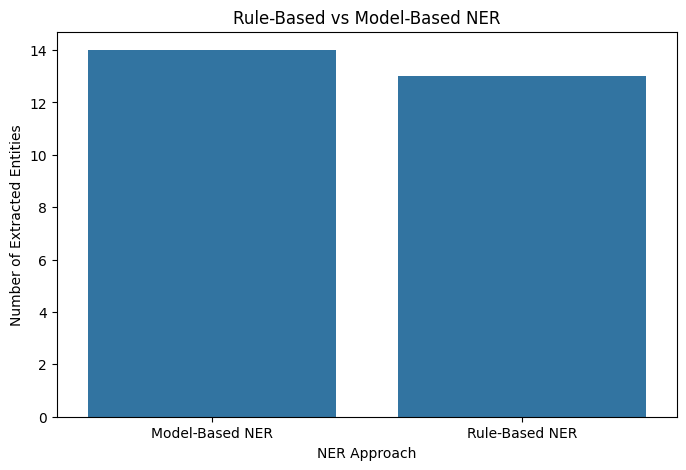

In [9]:
model_count = len(model_df)
rule_count = len(rule_df)

comparison = pd.DataFrame({
    "Approach": ["Model-Based NER", "Rule-Based NER"],
    "Extracted Entities": [model_count, rule_count]
})

print(comparison)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x="Approach",
    y="Extracted Entities"
)

plt.title("Rule-Based vs Model-Based NER")
plt.xlabel("NER Approach")
plt.ylabel("Number of Extracted Entities")
plt.show()

Visualize Named Entities using displaCy

In [10]:
sample_text = df.loc[0, "article"]

doc = nlp(sample_text)

print("News Article:")
print(sample_text)

print("\nHighlighted Named Entities:")

displacy.render(
    doc,
    style="ent",
    jupyter=True
)

News Article:
Microsoft CEO Satya Nadella visited London to discuss artificial intelligence and technology.

Highlighted Named Entities:


Entity Category Distribution

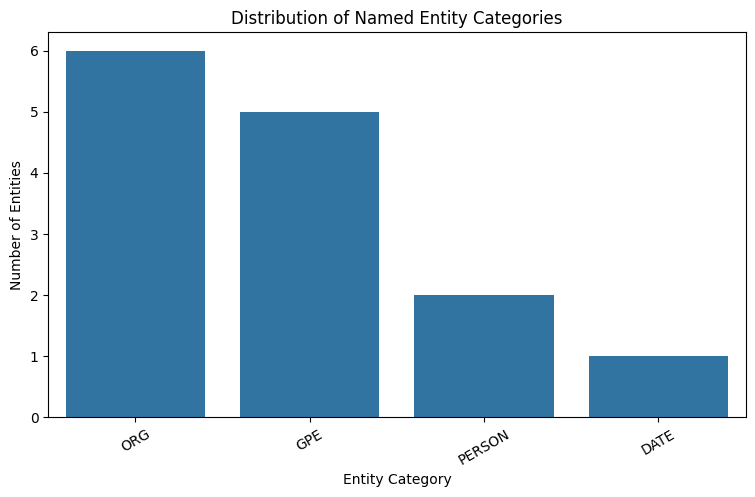

In [11]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=model_df,
    x="Entity Label",
    order=model_df["Entity Label"].value_counts().index
)

plt.title("Distribution of Named Entity Categories")
plt.xlabel("Entity Category")
plt.ylabel("Number of Entities")
plt.xticks(rotation=30)
plt.show()

Extract Unique Entities

In [12]:
print("Unique Named Entities:\n")

unique_entities = model_df.drop_duplicates(
    subset=["Entity", "Entity Label"]
)

display(
    unique_entities.sort_values("Entity Label")
)

Unique Named Entities:



,Article ID,Entity,Entity Label,Category
10,4,"January 15, 2026",DATE,Absolute or relative dates or periods
2,1,London,GPE,"Countries, cities, states"
5,2,New York,GPE,"Countries, cities, states"
7,3,California,GPE,"Countries, cities, states"
9,4,Paris,GPE,"Countries, cities, states"
13,5,Washington,GPE,"Countries, cities, states"
0,1,Microsoft,ORG,"Companies, agencies, institutions, etc."
3,2,OpenAI,ORG,"Companies, agencies, institutions, etc."
6,3,Google,ORG,"Companies, agencies, institutions, etc."
8,4,United Nations,ORG,"Companies, agencies, institutions, etc."


Testing

In [13]:
custom_article = """
Microsoft announced a technology partnership in London.
Satya Nadella discussed artificial intelligence with experts
from Google and OpenAI.
"""

custom_doc = nlp(custom_article)

print("Custom News Article:")
print(custom_article)

print("\nExtracted Entities:")

for ent in custom_doc.ents:
    print(ent.text, "---->", ent.label_, "---->", spacy.explain(ent.label_))

Custom News Article:

Microsoft announced a technology partnership in London.
Satya Nadella discussed artificial intelligence with experts
from Google and OpenAI.


Extracted Entities:
Microsoft ----> ORG ----> Companies, agencies, institutions, etc.
London ----> GPE ----> Countries, cities, states
Satya Nadella ----> PERSON ----> People, including fictional
Google ----> ORG ----> Companies, agencies, institutions, etc.
OpenAI ----> GPE ----> Countries, cities, states


Final Project Summary

In [14]:
print("=" * 45)
print("NAMED ENTITY RECOGNITION - PROJECT SUMMARY")
print("=" * 45)

print("Total News Articles:", len(df))
print("Model-Based Entities:", model_count)
print("Rule-Based Entities:", rule_count)

print("\nModel-Based NER Categories:")
print(model_df["Entity Label"].value_counts())

print("\nRule-Based NER Categories:")
print(rule_df["Entity Label"].value_counts())

print("\nProject Completed Successfully!")

NAMED ENTITY RECOGNITION - PROJECT SUMMARY
Total News Articles: 5
Model-Based Entities: 14
Rule-Based Entities: 13

Model-Based NER Categories:
Entity Label
ORG       6
GPE       5
PERSON    2
DATE      1
Name: count, dtype: int64

Rule-Based NER Categories:
Entity Label
ORG       6
GPE       5
PERSON    2
Name: count, dtype: int64

Project Completed Successfully!
